# T26 -- Phase 2 end-to-end integration, manual check

**Scope.** This notebook calls the ONE integrated Phase 2 pipeline
(`iste.phase2_pipeline.run_phase2_pipeline`, T26) and visualizes its result. No
scientific logic is reimplemented here -- every number/array plotted below comes
directly from the pipeline's own return value, which in turn comes entirely from
T14-T25's existing, unmodified public functions. No AIS attribution or formal
source-inference is computed anywhere.

**What this demonstrates**, end to end, on a small controlled synthetic case:

1. a tiny Stage III backward run (`iste.ensemble_run.run_ensemble`, unmodified --
   Stage III is run exactly ONCE, upstream, never re-run per candidate);
2. the Phase 2 pipeline over **two historical timestamps**, each producing
   **two spatially distinct candidates** (two synthetic upstream observation
   clusters, well separated);
3. for every candidate: support/KDE map + peak/core, core particle count `Y` and
   `N_forward = min(X,Y)`, weighted core-particle selection, forward propagation
   under coherent forcing members, predicted-vs-observed footprints, per-member
   forward accuracy, candidate-level aggregate, and final accept/reject + rank;
4. serialization of the final machine-readable candidate artifact and a reload.

**Distinguishing three concepts that must never be conflated** (`README.md`
Sec. 27/28):

- **backward support** (`support_score`/`density_score`/...) answers *why* a
  candidate was proposed -- it is retained purely as provenance;
- **forward consistency** (`candidate_forward_error`/`candidate_forward_consistency`)
  answers whether the candidate reproduces the observed slick well enough to
  survive -- it is the PRIMARY filtering/ranking signal;
- **candidate filtering/ranking** (accepted/rejected + rank) is a Phase 2
  **forward-screened candidate set**, explicitly **not a posterior, not a
  likelihood, and not a confirmed source**.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import tempfile
import matplotlib.pyplot as plt
import numpy as np

from iste.candidate_extraction import CandidateExtractionConfig
from iste.candidate_screening import ScreeningConfig
from iste.environment import GriddedFieldSource
from iste.ensemble_run import run_ensemble
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.forward_accuracy import ComparisonConfig
from iste.forward_budget import ForwardBudgetConfig
from iste.observation import adapt_upstream_particles
from iste.phase2_pipeline import Phase2RunConfig, run_phase2_pipeline, save_phase2_artifact, load_phase2_artifact
from iste.support_features import SupportFeatureConfig

## 1. Synthetic Stage III input (run exactly once, upstream)

A small ocean/forcing-ensemble setup, and 22 upstream observation particles in TWO
well-separated clusters (`px-0` near (20.0N,100.0E), `px-1` near (22.5N,103.0E)) --
so the Phase 2 pipeline should recover two distinct spatial candidate modes.
`iste.ensemble_run.run_ensemble` (T09, unmodified) produces the backward particle
history the Phase 2 pipeline queries from -- Stage III itself is never touched or
re-run by `iste.phase2_pipeline`.

In [2]:
LAT = np.linspace(15.0, 26.0, 23)
LON = np.linspace(95.0, 106.0, 23)
T_OBS = np.datetime64("2020-01-01T06:00:00", "ns")
N_HOURS = 8
TIME = T_OBS - (N_HOURS - 1) * np.timedelta64(3600, "s") + np.arange(N_HOURS) * np.timedelta64(3600, "s")

uo = np.full((N_HOURS, len(LAT), len(LON)), 0.15)
vo = np.full((N_HOURS, len(LAT), len(LON)), 0.05)
ocean = GriddedFieldSource(
    source_path="<synthetic>", time_name="time", time=TIME, lat_name="lat", lat=LAT,
    lon_name="lon", lon=LON, data={"uo": uo, "vo": vo}, fill_threshold=1e19,
)
ensemble_config = ForcingEnsembleConfig(
    n_members=4, spatial_correlation_km=40.0, correlation_time_seconds=2 * 3600.0,
    sigma_u=0.05, coarse_resolution_deg=0.5, master_seed=55,
)
ensemble = ForcingEnsemble(ocean, ensemble_config)
K = np.full((len(LAT), len(LON)), 1.0)

rng = np.random.default_rng(3)
n_a, n_b = 12, 10
lat_a = 20.0 + rng.normal(0.0, 0.03, n_a)
lon_a = 100.0 + rng.normal(0.0, 0.03, n_a)
lat_b = 22.5 + rng.normal(0.0, 0.03, n_b)
lon_b = 103.0 + rng.normal(0.0, 0.03, n_b)
obs_lat = np.concatenate([lat_a, lat_b])
obs_lon = np.concatenate([lon_a, lon_b])
records_upstream = [
    {"particle_id": f"o{i}", "latitude": obs_lat[i], "longitude": obs_lon[i],
     "observation_pixel_id": f"px-{0 if i < n_a else 1}", "timestamp": T_OBS}
    for i in range(len(obs_lat))
]
adapted = adapt_upstream_particles(records_upstream)

DT = 900.0
N_STEPS = 4
run_records = run_ensemble(
    adapted, forcing_member_ids=[0, 1], n_steps=N_STEPS, dt_seconds=DT,
    ocean_source=ocean, ensemble=ensemble, k_lat=LAT, k_lon=LON, k_field=K, master_seed=99,
)
print(f"Stage III: {len(run_records.particle_id)} (particle, member, checkpoint) rows")

Stage III: 220 (particle, member, checkpoint) rows


## 2. Phase 2 run configuration

An explicit historical timestamp grid (two timestamps), forcing-member set
`(0, 1)`, and every T14-T25 sub-configuration bundled into one
`Phase2RunConfig` -- including `master_seed`, the single seed every T19/T21 RNG
draw is deterministically derived from.

In [3]:
T_S_1 = T_OBS - np.timedelta64(900, "s")   # 15 min before t_obs
T_S_2 = T_OBS - np.timedelta64(1800, "s")  # 30 min before t_obs
support_lat_grid = np.linspace(18.0, 24.0, 61)
support_lon_grid = np.linspace(98.0, 105.0, 71)

config = Phase2RunConfig(
    historical_timestamps=(T_S_1, T_S_2), t_obs=T_OBS,
    support_query_lat_grid=support_lat_grid, support_query_lon_grid=support_lon_grid,
    neighborhood_radius_m=15000.0, support_config=SupportFeatureConfig(),
    extraction_config=CandidateExtractionConfig(peak_neighborhood_cells=3, min_separation_m=50000.0, core_radius_m=15000.0),
    forward_budget_config=ForwardBudgetConfig(X=8), forcing_member_ids=(0, 1), forward_dt_seconds=DT,
    footprint_lat_grid=support_lat_grid, footprint_lon_grid=support_lon_grid, footprint_bandwidth_m=5000.0,
    comparison_config=ComparisonConfig(metric="combined_overlap_fp"),
    screening_config=ScreeningConfig(mode="threshold", error_threshold=0.35, merge_separation_m=10000.0),
    master_seed=42,
)
print(f"historical timestamps: {[str(t) for t in config.historical_timestamps]}")

historical timestamps: ['2020-01-01T05:45:00.000000000', '2020-01-01T05:30:00.000000000']


## 3. Run the integrated Phase 2 pipeline

One call. Internally this invokes T14 (`query_particle_slice`) -> T15
(`build_particle_neighborhood_index`) -> T16 (`compute_support_map`) -> T17
(`find_candidate_peaks`) -> T18 (`compute_forward_particle_budget`) -> T19
(`sample_core_particles`) -> T20/T21 (`forward_propagate_candidate`) -> T22
(`build_observed_slick_footprint`/`build_predicted_slick_footprints`) -> T23
(`compare_predicted_footprints_to_observed`) -> T24
(`aggregate_candidate_forward_accuracy`) -> T25 (`filter_and_rank_candidates`) --
in that exact order, once per historical timestamp/candidate/forcing member.

In [4]:
result = run_phase2_pipeline(run_records, ocean, ensemble, LAT, LON, K, adapted, config)
print(f"n candidates total: {sum(len(ts.candidates) for ts in result.timestamps)}")
print(f"n decisions: {len(result.decisions)}")
for ts in result.timestamps:
    print(f"  t_s={ts.t_s}: {len(ts.candidates)} candidates")

n candidates total: 4
n decisions: 4
  t_s=2020-01-01T05:45:00.000000000: 2 candidates
  t_s=2020-01-01T05:30:00.000000000: 2 candidates


## 4. Visualization: every stage of the integrated pipeline, one figure

Row 1: T16/T17 support/KDE map with candidate peaks and core boundaries, for the
first historical timestamp. Row 2: T19 selected source-core particles + T20/T21
forward trajectories for each of that timestamp's candidates, plus a core-particle-
count (`Y`/`X`/`N_forward`) table for every candidate/time. Row 3: T22 observed
slick reference vs. each candidate's predicted footprint. Row 4: T23 per-member
forward accuracy. Row 5: T24 candidate-level aggregate + T25 final accept/reject
and rank.

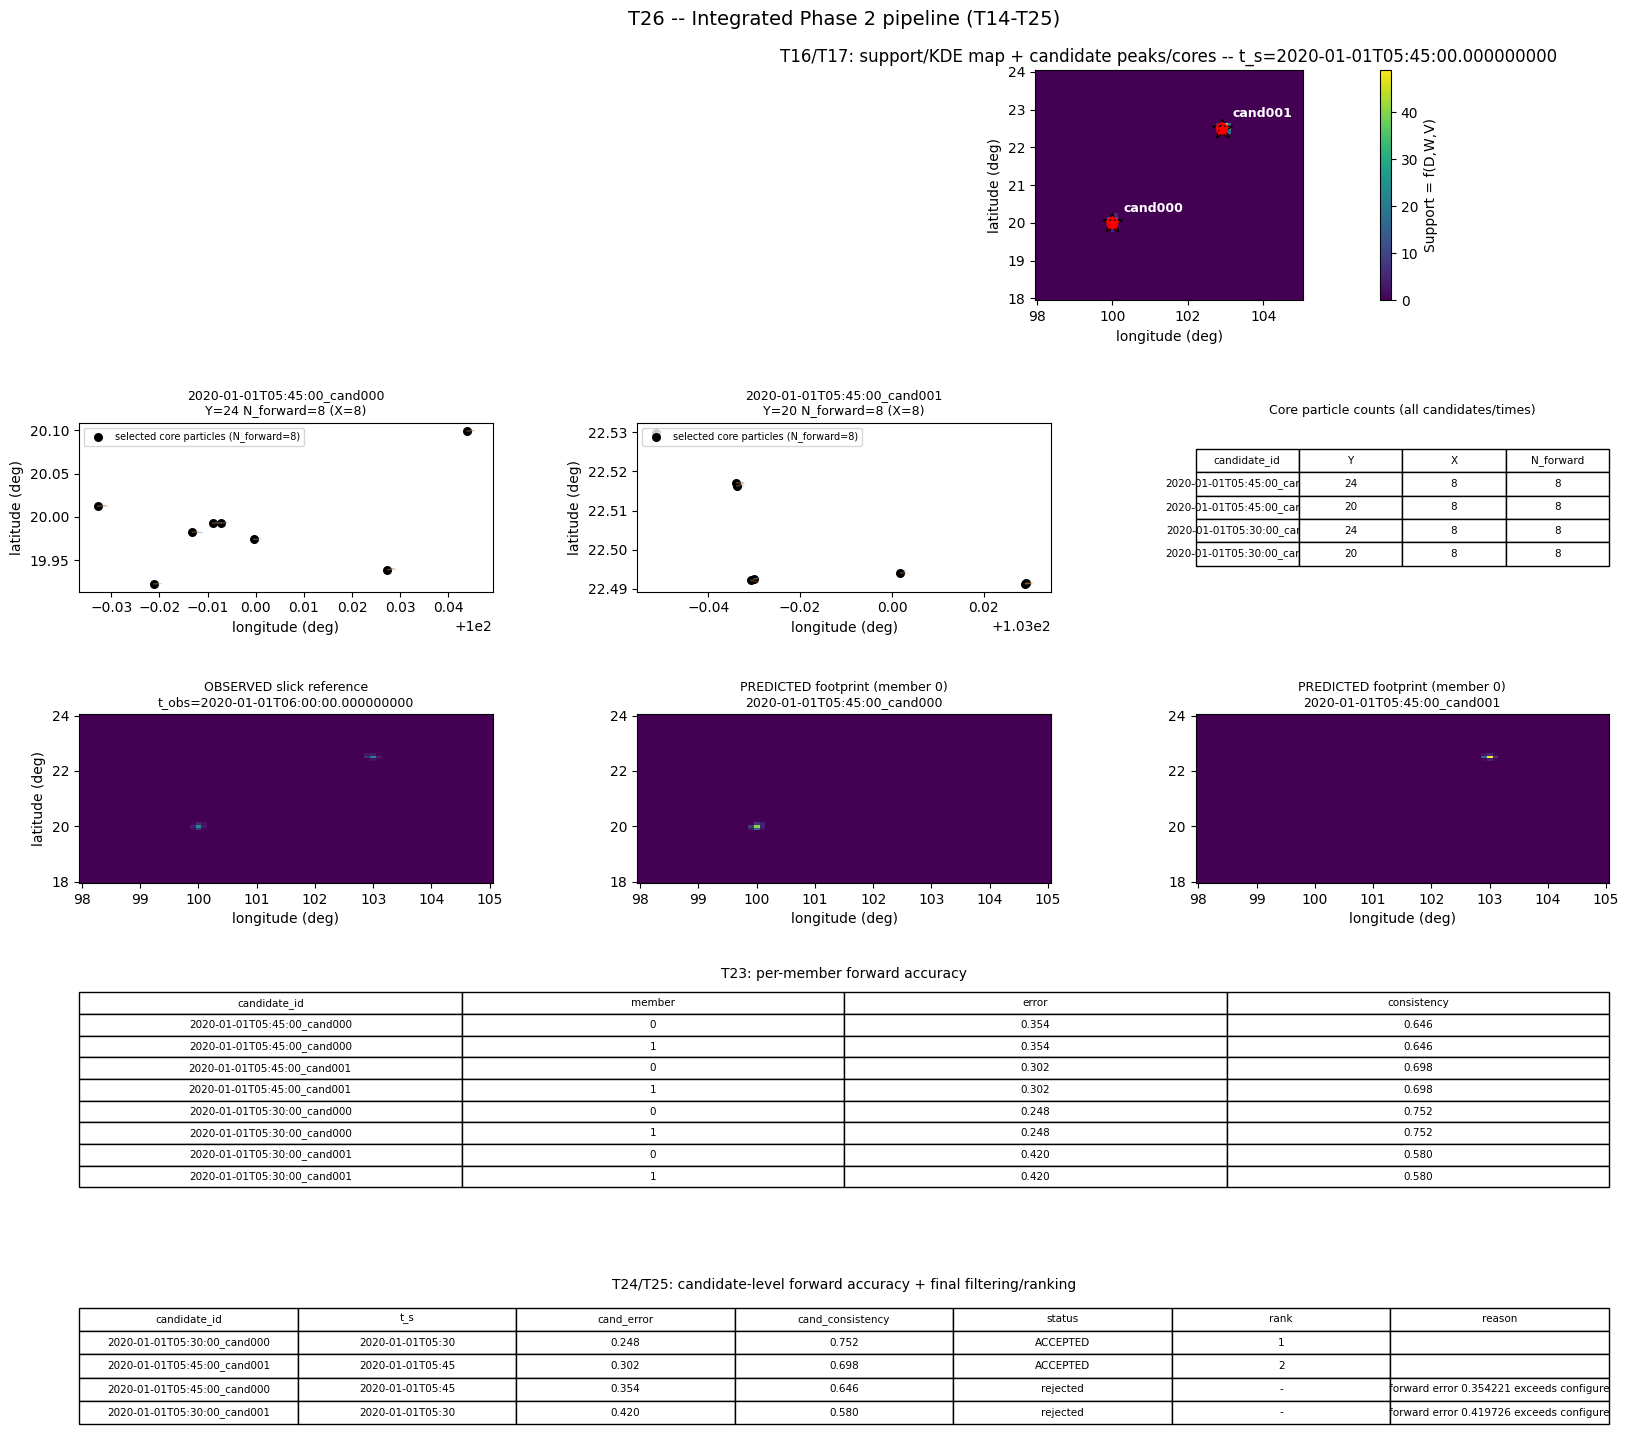

In [5]:
ts0 = result.timestamps[0]
support_grid = np.array([sf.support for sf in ts0.support_map]).reshape(len(support_lat_grid), len(support_lon_grid))

fig = plt.figure(figsize=(17, 15))
gs = fig.add_gridspec(
    5, 3, height_ratios=[3, 2.2, 2.2, 2.2, 1.8],
    hspace=0.7, wspace=0.35, top=0.94, bottom=0.03, left=0.05, right=0.95,
)

# --- Row 1: support/KDE map + candidate peaks/cores for t_s0 ---
ax = fig.add_subplot(gs[0, :])
mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, support_grid, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="Support = f(D,W,V)")
for c in ts0.candidates:
    ax.scatter([c.candidate.x_peak], [c.candidate.y_peak], marker="*", s=220, c="red", edgecolors="black", zorder=5)
    ax.annotate(c.candidate.candidate_id.split("_")[-1], (c.candidate.x_peak, c.candidate.y_peak),
                textcoords="offset points", xytext=(8, 8), color="white", fontsize=9, fontweight="bold")
    deg_per_m = 1.0 / 111_320.0
    circ = plt.Circle((c.candidate.x_peak, c.candidate.y_peak), c.candidate.core_region.radius_m * deg_per_m,
                       fill=False, edgecolor="red", linewidth=1.5, zorder=5)
    ax.add_patch(circ)
ax.set_title(f"T16/T17: support/KDE map + candidate peaks/cores -- t_s={ts0.t_s}")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)"); ax.set_aspect("equal")

# --- Row 2: source-core particles + forward trajectories, per candidate at t_s0 ---
colors_member = {0: "tab:blue", 1: "tab:orange"}
for i, c in enumerate(ts0.candidates[:2]):
    ax = fig.add_subplot(gs[1, i])
    ax.scatter(c.sampled.lon, c.sampled.lat, s=30, c="black", label=f"selected core particles (N_forward={c.budget.N_forward})")
    for member_id, run in c.forward_runs.runs.items():
        for p in range(run.n_particles):
            ax.plot(run.lon[:, p], run.lat[:, p], color=colors_member[member_id], alpha=0.4, linewidth=0.8)
    ax.set_title(f"{c.candidate.candidate_id}\nY={c.budget.Y} N_forward={c.budget.N_forward} (X={config.forward_budget_config.X})", fontsize=9)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
    ax.legend(fontsize=7, loc="upper left")
ax = fig.add_subplot(gs[1, 2])
ax.axis("off")
rows = [[c.candidate.candidate_id, c.budget.Y, config.forward_budget_config.X, c.budget.N_forward] for ts in result.timestamps for c in ts.candidates]
table = ax.table(cellText=rows, colLabels=["candidate_id", "Y", "X", "N_forward"], loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(7.5); table.scale(1, 1.4)
ax.set_title("Core particle counts (all candidates/times)", fontsize=9)

# --- Row 3: predicted vs observed footprints, member 0, both t_s0 candidates ---
vmax = max(np.nanmax(result.observed_footprint.density), *[np.nanmax(c.predicted_footprints[0].density) for c in ts0.candidates])
ax = fig.add_subplot(gs[2, 0])
ax.pcolormesh(support_lon_grid, support_lat_grid, result.observed_footprint.density, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
ax.set_title(f"OBSERVED slick reference\nt_obs={T_OBS}", fontsize=9)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
for i, c in enumerate(ts0.candidates[:2]):
    ax = fig.add_subplot(gs[2, i + 1])
    ax.pcolormesh(support_lon_grid, support_lat_grid, c.predicted_footprints[0].density, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"PREDICTED footprint (member 0)\n{c.candidate.candidate_id}", fontsize=9)
    ax.set_xlabel("longitude (deg)")

# --- Row 4: per-member forward accuracy table ---
ax = fig.add_subplot(gs[3, :])
ax.axis("off")
rows = []
for ts in result.timestamps:
    for c in ts.candidates:
        for member_id in config.forcing_member_ids:
            mr = c.member_results[member_id]
            rows.append([c.candidate.candidate_id, member_id, f"{mr.error:.3f}" if mr.valid else "invalid",
                         f"{mr.consistency:.3f}" if mr.valid else "invalid"])
table = ax.table(cellText=rows, colLabels=["candidate_id", "member", "error", "consistency"], loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(7.5); table.scale(1, 1.3)
ax.set_title("T23: per-member forward accuracy", fontsize=10, pad=20)

# --- Row 5: candidate-level aggregate + final accepted/rejected/ranks ---
ax = fig.add_subplot(gs[4, :])
ax.axis("off")
rows = []
for d in sorted(result.decisions, key=lambda d: (d.rank is None, d.rank if d.rank is not None else 0)):
    r = d.record
    rows.append([
        r.candidate_id, str(r.t_s)[:16],
        f"{r.candidate_forward_error:.3f}" if r.forward_validation_status == "validated" else "n/a",
        f"{r.candidate_forward_consistency:.3f}" if r.forward_validation_status == "validated" else "n/a",
        "ACCEPTED" if d.accepted else "rejected", d.rank if d.rank else "-", d.rejection_reason[:40],
    ])
table = ax.table(cellText=rows, colLabels=["candidate_id", "t_s", "cand_error", "cand_consistency", "status", "rank", "reason"], loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(7.5); table.scale(1, 1.4)
ax.set_title("T24/T25: candidate-level forward accuracy + final filtering/ranking", fontsize=10)

fig.suptitle("T26 -- Integrated Phase 2 pipeline (T14-T25)", fontsize=14)
plt.show()

## 5. Machine-readable artifact: serialize, reload, verify

In [6]:
with tempfile.TemporaryDirectory() as tmp_dir:
    artifact_path = os.path.join(tmp_dir, "phase2_artifact.json")
    save_phase2_artifact(result.decisions, config, artifact_path)
    reloaded = load_phase2_artifact(artifact_path)

required_fields = {
    "candidate_id", "x_s", "y_s", "t_s", "support_score", "density_score",
    "weighted_support_score", "pixel_diversity_score", "core_definition",
    "core_particle_count_Y", "forward_particle_count_N_forward", "sampling_seed",
    "forcing_members_validated", "forward_error_by_member", "forward_consistency_by_member",
    "candidate_forward_error", "candidate_forward_consistency", "accepted", "rank",
}
print(f"reloaded {len(reloaded['candidates'])} candidates")
for entry in reloaded["candidates"]:
    assert required_fields.issubset(entry.keys()), f"missing fields for {entry['candidate_id']}"
print("all required README Sec. 25 fields present on every reloaded candidate")

reloaded 4 candidates
all required README Sec. 25 fields present on every reloaded candidate


## Interpretation limits

- The final table above is a **forward-screened candidate set**, not a posterior,
  not a likelihood, and not a confirmed source (`README.md` Sec. 25/27/28).
- `support_score`/`density_score`/`weighted_support_score`/`pixel_diversity_score`
  (backward KDE support) are preserved purely as PROVENANCE ("why was this
  candidate proposed?") -- T25's `filter_and_rank_candidates` never reads them to
  decide accept/reject or rank.
- `candidate_forward_error`/`candidate_forward_consistency` (forward consistency)
  are a Phase 2 physical-consistency SCREENING quantity ("does this candidate
  reproduce the observed slick well enough to survive?") -- not a formal
  likelihood, not the Stage IV surrogate likelihood, and not a posterior
  probability.
- High backward support does not prove a source; low forward error is evidence of
  model-data consistency, not proof of the true source (`README.md` Sec. 27).
- No AIS attribution or final formal source inference is implemented here -- the
  serialized artifact above is explicitly the END of Phase 2, handed to a later,
  not-yet-implemented stage.